# TOVIS (*TO*nal *VIS*ualization toolbox): _Scale Analysis_
Johannes Zeitler and Meinard Müller, 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os

from tovis.feature import compute_chromagram_from_file, compute_chromagram_from_annotations
from tovis.scale import scale_analysis_templates, get_templates, generate_template_matrix
from tovis.visualization import plot_chromagram, plot_scale_likelihood, overlay_measure_annotations, overlay_structure_annotations
from tovis.utils import read_csv, get_exp_and_repr_limits, key_to_relative_major, time_to_measures, pitch_class_to_key_label

Specify BPSD directory and load annotations

In [2]:
BPSD_DIR = os.path.join("data", "BPSD")

piece = "Beethoven_Op014No2-01"
version = "WK64"

ann_audio_measure = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_measure", piece + "_" + version + ".csv"))
ann_audio_note = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_note", piece + "_" + version + ".csv"))
ann_audio_structureCoarse = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_structureCoarse", piece + "_" + version + ".csv"))
ann_audio_structureFine = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_structureFine", piece + "_" + version + ".csv"))
ann_score_structureCoarse = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_score_structureCoarse", piece + ".csv"))
ann_audio_localkey = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_localkey", piece + "_" + version + ".csv"))
ann_audio_syncinfo = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_syncInfo", piece + "_" + version + ".csv"))

global_key = key_to_relative_major(ann_audio_localkey.loc[0].localkey)

We first compute tonal features from audio recordings. In MIR, a popular choice is "chroma", or "pitch class", features. There are different methods to extract features, some based on signal processing (IIR, STFT, CQT), and others based on deep learning models. In the following, we will compare three methods for chroma extraction from audio. 

To obtain a temporally smooth feature representation, we apply a temporal smoothing filter (in our case: 4 seconds) to every estimated feature matrix. The features are then interpolated to exactly match a desired output feature rate (in our case: 1 Hz).

In [3]:
chromagram_IIR, sr_chromagram_IIR = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="IIR",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=1)

chromagram_STFT, sr_chromagram_STFT = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="STFT",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=1)

chromagram_CQT, sr_chromagram_CQT = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="CQT",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=1)


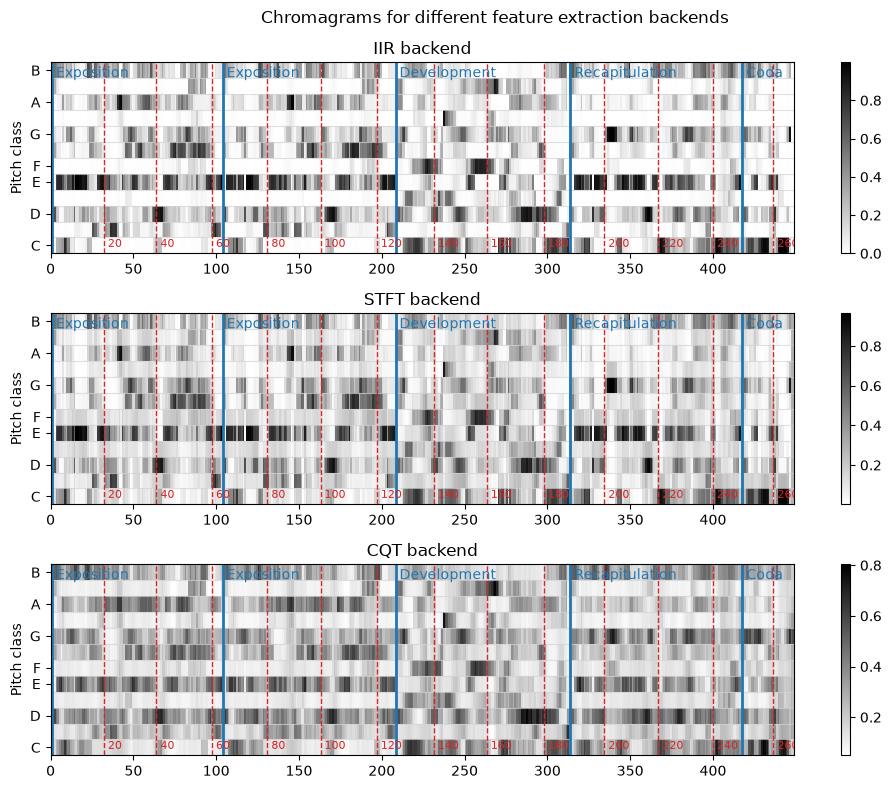

In [4]:
fig, ax = plt.subplots(3,1, figsize=(10, 8))
plot_chromagram(chromagram_IIR, feature_rate=sr_chromagram_IIR, ax=ax[0], title="IIR backend", xlabel=None, show_natural_pitch_labels=True)
plot_chromagram(chromagram_STFT, feature_rate=sr_chromagram_STFT, ax=ax[1], title="STFT backend", xlabel=None, show_natural_pitch_labels=True)
plot_chromagram(chromagram_CQT, feature_rate=sr_chromagram_CQT, ax=ax[2], title="CQT backend", xlabel=None, show_natural_pitch_labels=True)

for ax_ in ax:
    overlay_measure_annotations(ann_audio_measure,ax=ax_, measure_annotation_hop=20,)
    overlay_structure_annotations(ann_audio_structureCoarse,ax=ax_)

fig.suptitle("Chromagrams for different feature extraction backends")
fig.tight_layout()
plt.show()

To analyze the local key based on a chromagram representation, we do a frame-wise comparison of the chroma activations against template vectors that emphasize pitch classes present in a key and penalize those that are not inside the tonal material of a key. In the following, we display different templates for the C major scale.

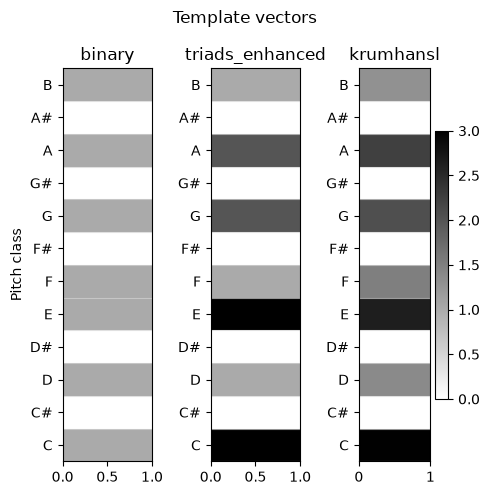

In [5]:
template_versions = ["binary", "triads_enhanced", "krumhansl"]
fig, ax = plt.subplots(1, len(template_versions), figsize=(5,5))

for i, vers in enumerate(template_versions):
    template = get_templates(vers)
    plot_chromagram(template, ax=ax[i], xlabel=None, title=vers, clim=[0,3], colorbar=(i>=2), ylabel="Pitch class" if i==0 else None)
    ax[i].set_xticks([])

fig.suptitle("Template vectors")
fig.tight_layout()
plt.show()

From a single template vector we can generate templates for all keys by cyclic shifting. Here, we display the resulting template matrix.

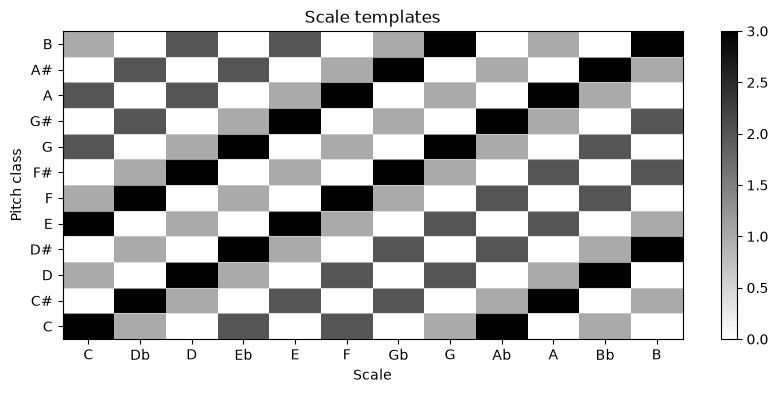

In [6]:
template_vector = get_templates("triads_enhanced")
template_matrix = generate_template_matrix(template_vector)

fig, ax, im = plot_chromagram(template_matrix, xlabel="Scale", title="Scale templates")
ax.set_xticks(np.arange(12)+.5)
ax.set_xticklabels([pitch_class_to_key_label(p) for p in np.arange(12)])
plt.show()

Next, we compare all templates in the template matrix against the frames of the chromagram and obtain a likelihood for every key. By sorting the likelihood matrix according to the circle of fifths and moving the global key to the vertical center of the plot, the figure becomes easier to understand. Note that we do not have to create the template vector and template matrix manually; this is done internally by ```scale_analysis_templates()``` when a ```template_version``` is specified. Applying softmax rescaling to the scale analysis output yields a matrix of scale likelihoods whose columns sum up to one.

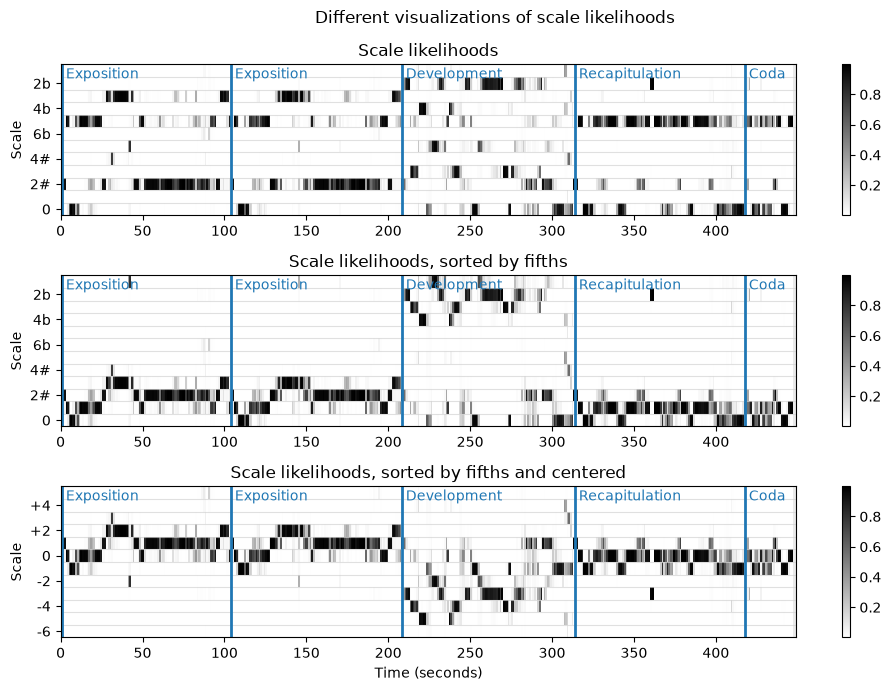

In [7]:
scale_likelihood_IIR = scale_analysis_templates(template_version="triads_enhanced",
                                            chromagram = chromagram_IIR,
                                            method="exp_product",
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)

fig, ax = plt.subplots(3,1, figsize=(10,7))

plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      ax=ax[0],
                      ytick_label_hop=2,
                      title="Scale likelihoods",
                      xlabel=None)



plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      ax=ax[1],
                      sort_by_fifths=True,
                      ytick_label_hop=2,
                      title="Scale likelihoods, sorted by fifths",
                      xlabel=None)

plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      ax=ax[2],
                      sort_by_fifths=True,
                      scale_label_version="relative_diatonic",
                      global_key = global_key,
                      ytick_label_hop=2,
                      title="Scale likelihoods, sorted by fifths and centered")

for ax_ in ax:
    #overlay_measure_annotations(ann_audio_measure,ax=ax_, measure_annot_hop=20)
    overlay_structure_annotations(ann_audio_structureCoarse,ax=ax_)

fig.suptitle("Different visualizations of scale likelihoods")
fig.tight_layout()
plt.show()


To highlight the importance of the feature extraction method, we compute scale likelihoods based on different feature extractors and also a symbolic score representation. To this end, we bring the estimated features to a musical time axis. In the bottom plot, we use a C(yan)-M(agenta)-Y(ellow) overlay of the different methods to enable intuitive comparison.

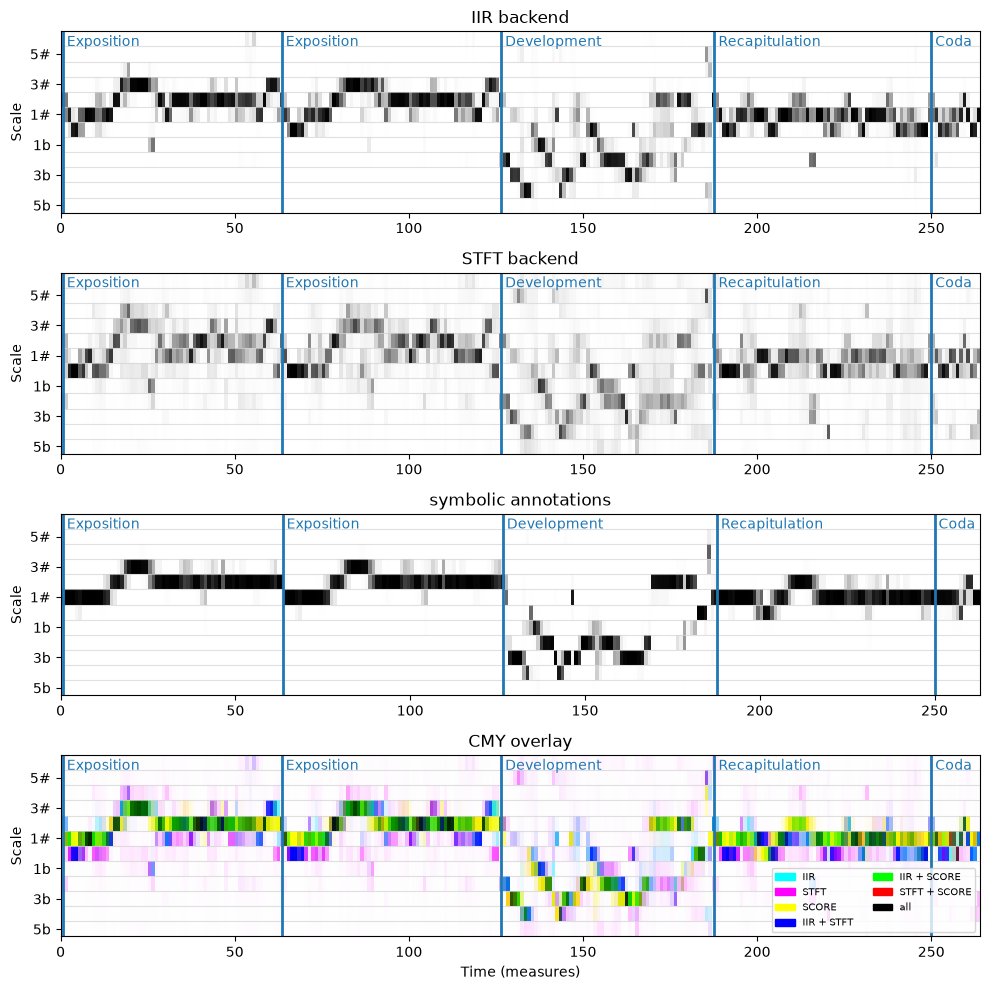

In [8]:
chromagram_score, sr_chromagram_score = compute_chromagram_from_annotations(ann_audio_note,
                                                                            start_column="start_meas",
                                                                            end_column="end_meas",
                                                                            feature_rate=16,
                                                                            smoothing_length_seconds=4,
                                                                            output_feature_rate=1)

scale_likelihood_score = scale_analysis_templates(template_version="triads_enhanced",
                                            chromagram = chromagram_score,
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)

scale_likelihood_IIR_measures, _ = time_to_measures(scale_likelihood_IIR,
                                                    sync_annotation=ann_audio_syncinfo,
                                                    feature_rate=sr_chromagram_IIR,
                                                    frames_per_measure=sr_chromagram_score)

scale_likelihood_STFT = scale_analysis_templates(template_version="triads_enhanced",
                                            chromagram = chromagram_STFT,
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)

scale_likelihood_STFT_measures, _ = time_to_measures(scale_likelihood_STFT,
                                                    sync_annotation=ann_audio_syncinfo,
                                                    feature_rate=sr_chromagram_STFT,
                                                    frames_per_measure=sr_chromagram_score)
fig, ax = plt.subplots(4,1, figsize=(10,10))
plot_scale_likelihood(scale_likelihood_IIR_measures,
                      feature_rate=sr_chromagram_score,
                      ax=ax[0],
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key = global_key,
                      ytick_label_hop=2,
                      title="IIR backend",
                      colorbar=False,
                      xlabel=None)

plot_scale_likelihood(scale_likelihood_STFT_measures,
                      feature_rate=sr_chromagram_score,
                      ax=ax[1],
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key = global_key,
                      ytick_label_hop=2,
                      title="STFT backend",
                      colorbar=False,
                      xlabel=None)

plot_scale_likelihood(scale_likelihood_score,
                      feature_rate=sr_chromagram_score,
                      ax=ax[2],
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key = global_key,
                      ytick_label_hop=2,
                      title="symbolic annotations",
                      colorbar=False,
                      xlabel=None)

plot_scale_likelihood([scale_likelihood_IIR_measures, scale_likelihood_STFT_measures, scale_likelihood_score],
                      overlay_labels=["IIR", "STFT", "SCORE"],
                      feature_rate=sr_chromagram_score,
                      ax=ax[3],
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key = global_key,
                      ytick_label_hop=2,
                      title="CMY overlay",
                      xlabel="Time (measures)")

for ax_ in ax:
    overlay_structure_annotations(ann_score_structureCoarse,ax=ax_)


fig.tight_layout()
plt.show()

By cropping to the exposition and recapitulation, we can precisely analyze the different harmonic progressions in these parts.

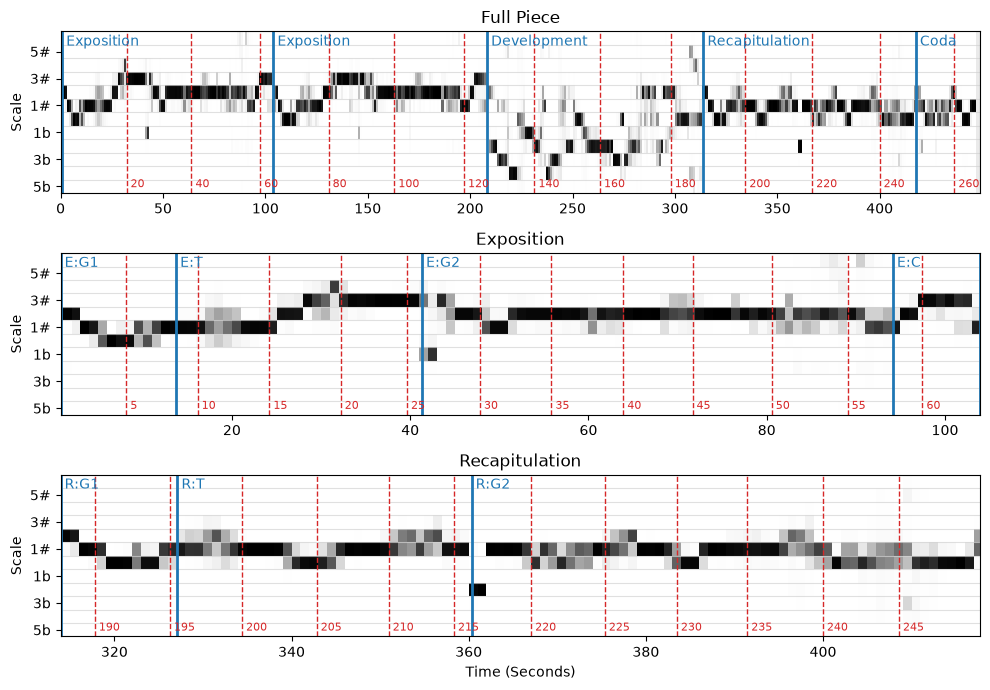

In [9]:
limits_exp, limits_repr = get_exp_and_repr_limits(ann_audio_structureCoarse)

fig, ax = plt.subplots(3,1, figsize=(10,7))

# full piece
plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key=global_key,
                      ax=ax[0],
                      ytick_label_hop=2,
                      title="Full Piece",
                      colorbar=False,
                      xlabel=None)
overlay_measure_annotations(ann_audio_measure,ax=ax[0], measure_annotation_hop=20)
overlay_structure_annotations(ann_audio_structureCoarse,ax=ax[0])

# exposition
plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key=global_key,
                      ax=ax[1],
                      ytick_label_hop=2,
                      title="Exposition",
                      colorbar=False,
                      xlim=limits_exp,
                      xlabel=None)
overlay_measure_annotations(ann_audio_measure,ax=ax[1], measure_annotation_hop=5)
overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                              ax=ax[1])

# recap
plot_scale_likelihood(scale_likelihood_IIR,
                      feature_rate=sr_chromagram_IIR,
                      sort_by_fifths=True,
                      scale_label_version="absolute_diatonic",
                      global_key=global_key,
                      ax=ax[2],
                      ytick_label_hop=2,
                      title="Recapitulation",
                      colorbar=False,
                      xlim=limits_repr,
                      xlabel="Time (Seconds)")
overlay_measure_annotations(ann_audio_measure,ax=ax[2], measure_annotation_hop=5)
overlay_structure_annotations(ann_audio_structureFine,
                              shorten_annotation=True,
                              ax=ax[2])

fig.tight_layout()
plt.show()


Another possibility for analysis is the comparison across multiple versions of the same piece. Therefore, we extract audio features from all versions, bring them to a unified musical time axis, and overlay the result.

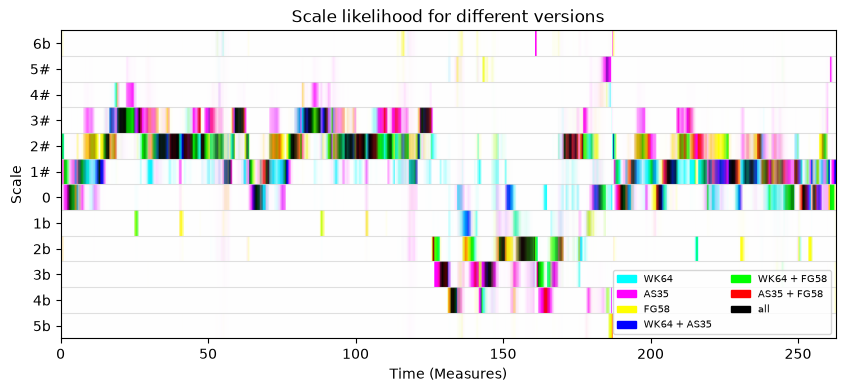

In [10]:
versions = ["WK64", "AS35", "FG58"]
scale_likelihoods_measures = []

frames_per_measure=4

for i, version in enumerate(versions):
    chromagram, sr_chromagram = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                         backend="IIR",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=1)
    
    scale_likelihood = scale_analysis_templates(template_version="triads_enhanced",
                                            chromagram = chromagram,
                                            method = "exp_product",
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)
    
    ann_audio_measure = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_measure", piece + "_" + version + ".csv"))

    scale_likelihood_measures, measure_axis = time_to_measures(scale_likelihood, 
                                                               sync_annotation=ann_audio_measure,
                                                               feature_rate=sr_chromagram, 
                                                               frames_per_measure=frames_per_measure)
    
    scale_likelihoods_measures.append(scale_likelihood_measures)


fig, ax, im = plot_scale_likelihood(scale_likelihoods_measures, 
                                    feature_rate=frames_per_measure,
                                    xlabel="Time (Measures)",
                                    sort_by_fifths=True,
                                    scale_label_version="absolute_diatonic",
                                    global_key=global_key,
                                    overlay_labels=versions,
                                    title="Scale likelihood for different versions")
